# K-Means Clustering: Grouping Districts by Crime Profiles

## Project Objective
Analyze Indian districts based on historical reported crime patterns using regression, classification, and clustering to identify comparatively lower/higher reported crime levels and groups of districts with similar crime profiles.

This notebook implements **K-Means Clustering** to group Indian districts into clusters based on similarities in their historical reported crime profiles. 

*(Note: K-Means is only identifying groups of districts with similar crime-feature patterns. It does not classify districts as objectively "safe" or "dangerous").*

## Step 1 — Load the Data

We load our primary dataset and filter out the `TOTAL` summary rows, exactly as we did for our previous supervised models.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
file_path = '../data/factors/crime/01_District_wise_crimes_committed_IPC_2001_2012.csv'
df = pd.read_csv(file_path)

# Filter summary rows
df_clean = df[~df['DISTRICT'].isin(['TOTAL', 'DELHI UT TOTAL'])].copy()

# Display initial insights
print(f"Cleaned Data Shape: {df_clean.shape}")
print(f"Unique Districts: {df_clean['DISTRICT'].nunique()}")
print(f"Unique States/UTs: {df_clean['STATE/UT'].nunique()}")

print("\nFirst 5 rows:")
display(df_clean.head())

Cleaned Data Shape: (8597, 33)
Unique Districts: 806
Unique States/UTs: 35

First 5 rows:


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,...,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,...,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,...,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,...,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,...,41,1244,12,109,58,247,0,431,2313,6507


## Step 2 — Why K-Means is Different

Previous models (Linear Regression, Decision Trees, Random Forest, KNN) were **Supervised Learning** algorithms. They had a specific target variable (`Violent Crime Level`) and were used for prediction.

K-Means is an **Unsupervised Learning** algorithm:
* There is NO target variable.
* It groups observations purely based on mathematical similarity.
* It calculates distances between observations in feature space.
* Observations closer to each other are automatically assigned to the same cluster.

**In simple terms:** K-Means tries to place similar districts into the same group based on their crime-feature values. 

*(Note: "Similarity" here refers to mathematical similarity in feature space, NOT geographical distance. Districts in completely different states can be grouped together if their crime profiles match).*

## Step 3 — Create District-Level Historical Profiles

For K-Means, we do NOT want one row for every district-year combination. Instead, we want exactly **one row per district** representing its overall historical profile.

We achieve this by grouping by `DISTRICT` and calculating the mean (average) across all available years (2001-2012) for our 9 core crime features.

**Why we exclude certain columns:**
* `DISTRICT` and `STATE/UT` are categorical identifiers, not numerical crime metrics.
* `YEAR` is irrelevant because we are building a historical average across all years.
* `TOTAL IPC CRIMES` is a derived sum. Including it would distort the distances.
* `Violent Crime Score`, `Property Crime Score`, and `Violent Crime Level` are project-created composite variables and prediction targets. Including them would unfairly duplicate the raw data.

In [2]:
# Define our core 9 crime features
features = [
    'MURDER', 'ATTEMPT TO MURDER', 'RAPE', 'KIDNAPPING & ABDUCTION', 
    'THEFT', 'BURGLARY', 'ROBBERY', 'RIOTS', 'CHEATING'
]

# Calculate the historical average for each district
cluster_data = df_clean.groupby('DISTRICT')[features].mean().reset_index()

print("District-level profiles created successfully!")

District-level profiles created successfully!


## Step 4 — Check the Clustering Data

In [3]:
print(f"Shape of cluster data: {cluster_data.shape}\n")

print(f"Missing values across the 9 features: {cluster_data[features].isnull().sum().sum()}\n")

print("Descriptive Statistics:")
display(cluster_data[features].describe().round(2))

print("\nFirst 5 Rows of Cluster Data:")
display(cluster_data.head())

Shape of cluster data: (806, 10)

Missing values across the 9 features: 0

Descriptive Statistics:


,MURDER,ATTEMPT TO MURDER,RAPE,KIDNAPPING & ABDUCTION,THEFT,BURGLARY,ROBBERY,RIOTS,CHEATING
count,806.00,806.00,806.00,806.00,806.00,806.00,806.00,806.00,806.00
mean,45.08,40.12,27.19,41.65,416.33,131.35,28.40,90.70,96.51
std,40.15,41.20,27.56,50.99,824.33,209.21,44.51,136.92,187.31
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,18.71,12.50,8.69,11.12,92.65,28.50,6.77,10.75,15.27
50%,36.00,28.21,20.33,25.46,214.08,81.62,17.50,46.21,40.29
75%,59.69,54.73,37.50,53.33,435.08,166.29,33.92,108.98,100.19
max,382.17,338.92,279.33,442.17,12195.00,2845.14,561.67,1729.80,2200.08



First 5 Rows of Cluster Data:


,DISTRICT,MURDER,ATTEMPT TO MURDER,RAPE,KIDNAPPING & ABDUCTION,THEFT,BURGLARY,ROBBERY,RIOTS,CHEATING
0,24 PARGANAS NORTH,194.083333,105.166667,156.916667,275.916667,1832.166667,32.250000,61.583333,457.000000,180.666667
1,24 PARGANAS SOUTH,176.166667,16.750000,185.083333,184.083333,1535.500000,46.333333,32.666667,741.083333,115.750000
2,A and N ISLANDS,15.000000,19.000000,3.000000,12.000000,112.000000,90.000000,9.000000,17.000000,23.000000
3,ADILABAD,98.833333,72.416667,56.000000,62.833333,330.333333,209.916667,19.750000,84.666667,161.000000
4,AGRA,134.083333,151.333333,41.083333,211.750000,1727.083333,255.250000,101.666667,273.250000,276.916667


## Step 5 — Standardize the Features

**Why feature scaling is important for K-Means:**
K-Means strictly uses distance calculations (like drawing physical lines between data points). Our crime variables have vastly different numerical ranges. For example, `THEFT` averages around 350-500 counts per year, while `ROBBERY` averages around 20-30 counts. If we don't scale the data, K-Means will essentially ignore Robbery and build clusters entirely based on Theft simply because the numbers are bigger.

We use `StandardScaler` to transform each feature so it is centered around 0 with a standard deviation of 1, giving every crime type an equal voice in the clustering.

*(Note: There is no train/test split here because this is descriptive historical clustering, not future prediction).*

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit and transform the features
X_scaled = scaler.fit_transform(cluster_data[features])

print("Features successfully standardized!")

Features successfully standardized!


## Step 6 — Determine a Reasonable Number of Clusters (K)

We use the **Elbow Method** to find a good value for K (the number of clusters). We test K from 2 to 10 and collect the "Inertia".

* **What is Inertia?** It measures how close the observations are to the center of their assigned cluster. Lower inertia means more compact clusters. Increasing K will naturally reduce inertia. We look for the "elbow" in the plot where the reduction in inertia starts becoming less substantial.

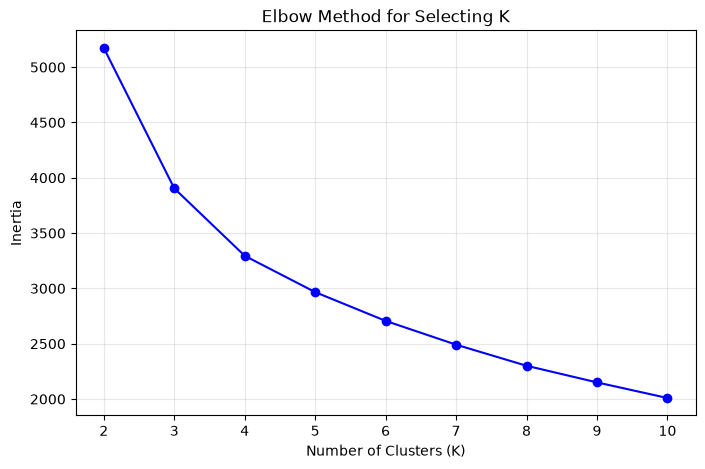

In [5]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o', linestyle='-', color='b')
plt.title('Elbow Method for Selecting K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()

## Step 7 — Silhouette Score Check (Optional Diagnostic)

A higher silhouette score generally indicates better separation between clusters. We use this as a supporting diagnostic alongside the elbow plot to confirm our choice.

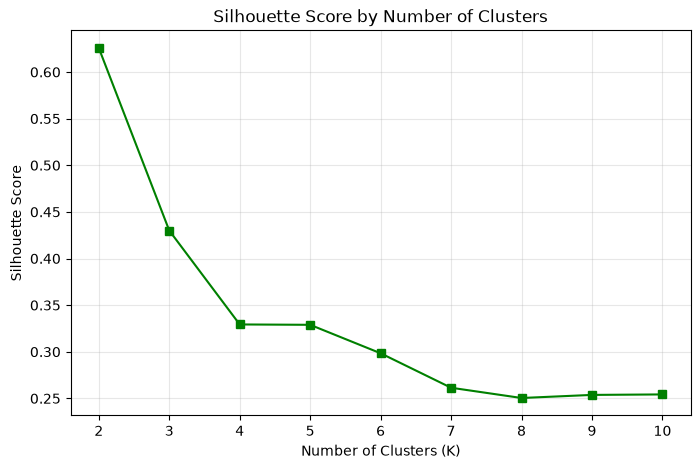

In [6]:
from sklearn.metrics import silhouette_score

silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouettes.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouettes, marker='s', linestyle='-', color='g')
plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()

## Step 8 — Train the Final K-Means Model

Looking at the Elbow Plot, the drop in inertia begins to smooth out noticeably after K=4. The Silhouette Score is highest at K=2 and K=3, but K=4 still maintains a strong score while providing more granular, interesting groupings than a simple binary split. Therefore, we will proceed with **K=4**.

*(Note: The elbow method does not give a mathematically perfect K; it is a heuristic to find a reasonable balance).*

In [7]:
SELECTED_K = 4

# Create final model
kmeans = KMeans(
    n_clusters=SELECTED_K,
    random_state=42,
    n_init=10
)

# Fit and generate labels
cluster_labels = kmeans.fit_predict(X_scaled)

# Add the labels back to our district dataset
cluster_data["Cluster"] = cluster_labels

print("Districts in each cluster:")
display(cluster_data["Cluster"].value_counts().sort_index())

print("\nFirst 10 Rows with Cluster Labels:")
display(cluster_data.head(10))

Districts in each cluster:


Cluster
0    455
1     50
2    298
3      3
Name: count, dtype: int64


First 10 Rows with Cluster Labels:


,DISTRICT,MURDER,ATTEMPT TO MURDER,RAPE,KIDNAPPING & ABDUCTION,THEFT,BURGLARY,ROBBERY,RIOTS,CHEATING,Cluster
0,24 PARGANAS NORTH,194.083333,105.166667,156.916667,275.916667,1832.166667,32.250000,61.583333,457.000000,180.666667,1
1,24 PARGANAS SOUTH,176.166667,16.750000,185.083333,184.083333,1535.500000,46.333333,32.666667,741.083333,115.750000,1
2,A and N ISLANDS,15.000000,19.000000,3.000000,12.000000,112.000000,90.000000,9.000000,17.000000,23.000000,0
3,ADILABAD,98.833333,72.416667,56.000000,62.833333,330.333333,209.916667,19.750000,84.666667,161.000000,2
4,AGRA,134.083333,151.333333,41.083333,211.750000,1727.083333,255.250000,101.666667,273.250000,276.916667,1
5,AHMEDABAD COMMR.,100.333333,64.833333,42.166667,191.750000,4804.583333,782.666667,441.000000,202.833333,264.416667,1
6,AHMEDABAD RURAL,34.500000,15.916667,7.083333,38.833333,299.333333,109.833333,29.083333,57.250000,13.666667,0
7,AHMEDNAGAR,100.833333,67.916667,54.416667,42.833333,1200.416667,437.333333,128.583333,395.166667,168.583333,1
8,AHWA-DANG,6.500000,1.083333,2.416667,0.500000,8.666667,4.250000,0.750000,4.250000,1.500000,0
9,AIZAWL,11.750000,10.583333,28.750000,3.166667,433.416667,193.000000,4.333333,1.333333,37.750000,0


## Step 9 — Analyze Cluster Profiles

This is the most important part of clustering: understanding what the clusters actually represent mathematically. 

We calculate the historical average crime counts for the districts inside each cluster. We also create a **heatmap using standardized values** to easily visualize which crimes are exceptionally high or low in a given cluster relative to the national average.

Average Raw Crime Counts per Cluster:


,MURDER,ATTEMPT TO MURDER,RAPE,KIDNAPPING & ABDUCTION,THEFT,BURGLARY,ROBBERY,RIOTS,CHEATING
Cluster,,,,,,,,,
0,22.8,18.3,13.0,18.7,170.5,58.2,11.4,36.0,38.5
1,126.4,119.1,74.8,162.6,1677.7,421.5,111.8,254.0,336.3
2,63.6,58.4,39.8,54.7,477.0,171.0,36.2,144.7,127.5
3,235.7,211.1,135.6,200.1,10656.1,2447.2,446.7,305.1,1826.2


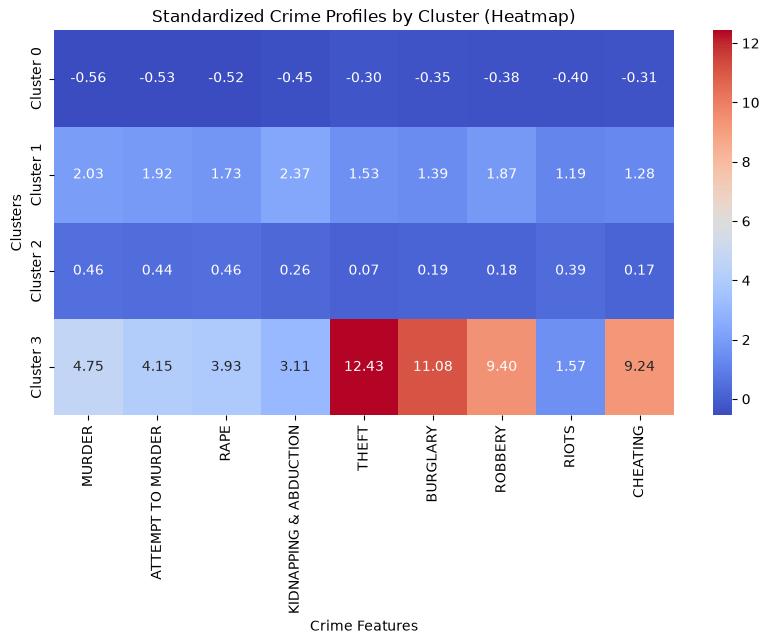

In [8]:
import seaborn as sns

# Calculate raw average counts per cluster
cluster_profile = cluster_data.groupby("Cluster")[features].mean()

print("Average Raw Crime Counts per Cluster:")
display(cluster_profile.round(1))

# For a heatmap, we should visualize the STANDARDIZED cluster centers 
# so we can compare patterns fairly without Theft drowning everything out.
plt.figure(figsize=(10, 5))
sns.heatmap(kmeans.cluster_centers_, annot=True, cmap='coolwarm', fmt=".2f", 
            xticklabels=features, yticklabels=[f"Cluster {i}" for i in range(SELECTED_K)])
plt.title('Standardized Crime Profiles by Cluster (Heatmap)')
plt.xlabel('Crime Features')
plt.ylabel('Clusters')
plt.show()

## Step 10 — Identify Example Districts in Each Cluster

Let's look at a few example districts that were mathematically grouped into each cluster. 
*(Remember: We are not ranking districts as best or worst, just viewing examples of districts sharing similar historical crime profiles).*

In [9]:
for cluster in sorted(cluster_data["Cluster"].unique()):
    print(f"\n--- Cluster {cluster} Examples ---")
    display(
        cluster_data[cluster_data["Cluster"] == cluster]
        .sort_values("THEFT", ascending=False)
        [["DISTRICT", "MURDER", "RAPE", "THEFT", "ROBBERY", "RIOTS"]]
        .head(7).round(1)
    )


--- Cluster 0 Examples ---


,DISTRICT,MURDER,RAPE,THEFT,ROBBERY,RIOTS
505,MUMBAI RLY.,8.1,2.6,1800.3,68.7,10.3
242,G.R.P.(RLY),8.6,1.6,1169.8,9.8,0.6
612,RAJKOT COMMR.,35.2,7.8,1104.4,36.8,81.8
101,BHOPAL RLY.,4.5,1.7,1025.1,19.9,4.4
520,NAGPUR RLY.,6.6,0.9,933.7,24.9,10.2
161,COIMBATORE URBAN,21.8,8.3,898.7,28.9,66.2
791,W.RLY,13.3,1.6,876.2,54.2,9.2



--- Cluster 1 Examples ---


,DISTRICT,MURDER,RAPE,THEFT,ROBBERY,RIOTS
5,AHMEDABAD COMMR.,100.3,42.2,4804.6,441.0,202.8
304,HYDERABAD CITY,121.2,59.3,4680.6,78.5,202.7
591,PUNE COMMR.,109.8,70.5,4074.8,305.6,540.8
321,JAIPUR,87.8,67.6,3488.2,64.0,1729.8
422,KOLKATA,49.7,36.1,3443.1,83.9,249.4
312,INDORE,111.6,104.6,3406.8,193.8,134.7
174,CYBERABAD,181.0,64.1,2966.5,76.5,55.9



--- Cluster 2 Examples ---


,DISTRICT,MURDER,RAPE,THEFT,ROBBERY,RIOTS
782,VIJAYAWADA,42.6,26.8,2455.6,40.8,12.4
322,JAIPUR EAST,19.6,27.6,2318.7,91.6,102.4
280,GURGAON,77.8,33.9,2043.3,76.8,89.9
724,SURAT COMMR.,92.3,25.9,1945.0,71.9,100.6
707,SOUTH WEST,50.5,61.5,1629.2,58.2,22.5
257,GAUTAMBUDH NAGAR,78.7,21.2,1551.1,89.0,78.6
139,CHANDIGARH,20.2,23.4,1539.5,33.1,62.9



--- Cluster 3 Examples ---


,DISTRICT,MURDER,RAPE,THEFT,ROBBERY,RIOTS
504,MUMBAI COMMR.,220.3,198.0,12195.0,458.4,337.7
503,MUMBAI,250.8,155.2,10987.2,320.0,188.8
61,BANGALORE COMMR.,235.9,53.5,8786.2,561.7,388.8


## Step 11 — Visualize the Clusters (PCA)

Because we clustered based on 9 different crime features, our clusters exist in a 9-dimensional mathematical space. Human eyes can only see in 2 or 3 dimensions. 

To visualize our clusters on a flat screen, we use **PCA (Principal Component Analysis)**. PCA is used here strictly to compress the 9-dimensional standardized feature space down to 2 dimensions for visualization. **PCA is NOT being used to perform the K-Means clustering itself.**

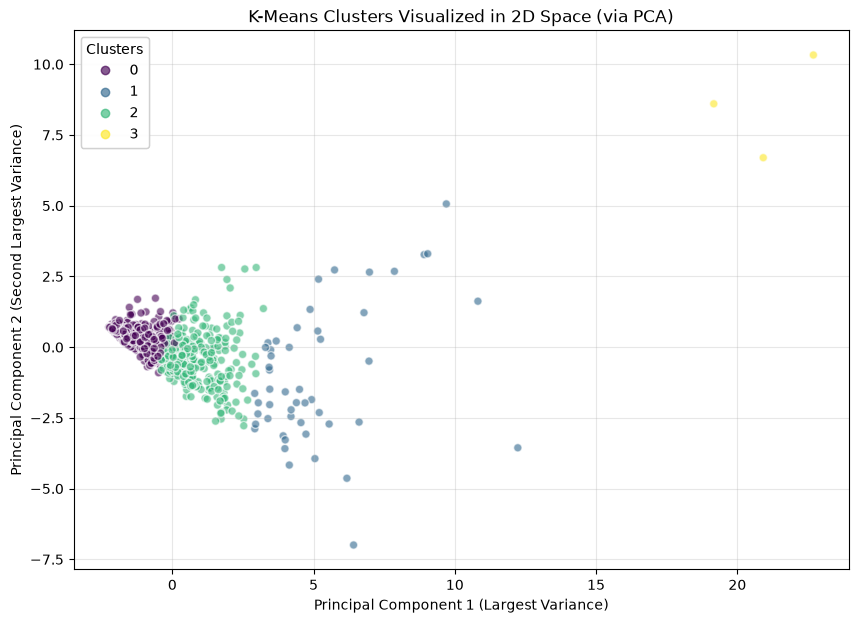

In [10]:
from sklearn.decomposition import PCA

# Reduce to 2 dimensions for plotting
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

# Scatter plot of the 2 PCA components, colored by Cluster label
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6, edgecolors='w')

plt.title('K-Means Clusters Visualized in 2D Space (via PCA)')
plt.xlabel('Principal Component 1 (Largest Variance)')
plt.ylabel('Principal Component 2 (Second Largest Variance)')

# Add legend
legend1 = plt.legend(*scatter.legend_elements(), title="Clusters")
plt.gca().add_artist(legend1)

plt.grid(True, alpha=0.3)
plt.show()

## Save Model for Streamlit

Saving the trained model and required preprocessing objects so they can be loaded by the Streamlit application.

In [11]:
import joblib
import os
os.makedirs('../models', exist_ok=True)
joblib.dump(kmeans, "../models/kmeans_model.joblib")
joblib.dump(scaler, "../models/kmeans_scaler.joblib")

['../models/kmeans_scaler.joblib']